In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [18]:
import math
import torch
import torchvision
import torchvision.transforms as transforms

# =====================================================================
# 1. CẤU HÌNH VÀ CHUẨN BỊ DỮ LIỆU (DATA SETUP)
# =====================================================================
print("Đang tải dữ liệu và tính toán thông số chuẩn hóa...")

# Bước 1: Tải tập dữ liệu thô để tính mean và std chính xác (đã chia 255)
raw_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
raw_data_normalized = raw_train.data.float() / 255.0

pixel_mean = raw_data_normalized.mean().item()
pixel_std = raw_data_normalized.std().item()

print(f"  > Pixel Mean tính toán động: {pixel_mean:.4f}")
print(f"  > Pixel Std tính toán động: {pixel_std:.4f}")

# Bước 2: Tạo bộ transform động chuẩn hoá dữ liệu dựa trên mean và std tính toán
dynamic_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((pixel_mean,), (pixel_std,))
])

# Bước 3: Khởi tạo Dataset với transform chuẩn
train_dataset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=dynamic_transform
)
test_dataset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=dynamic_transform
)

# Bước 4: Tạo DataLoader
batch_size = 64
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

print(f"Data setup hoàn tất! Tập Train: {len(train_dataset)} ảnh | Tập Test: {len(test_dataset)} ảnh.")
print("-" * 60)

def to_one_hot(y, num_classes=10):
    """Chuyển đổi nhãn indices thành ma trận một-hot dạng Float32 an toàn."""
    one_hot = torch.zeros(y.size(0), num_classes, device=y.device, dtype=torch.float32)
    one_hot[range(y.size(0)), y] = 1.0
    return one_hot


Đang tải dữ liệu và tính toán thông số chuẩn hóa...
  > Pixel Mean tính toán động: 0.1307
  > Pixel Std tính toán động: 0.3081
Data setup hoàn tất! Tập Train: 60000 ảnh | Tập Test: 10000 ảnh.
------------------------------------------------------------


In [19]:
class SoftmaxClassifier:
    def __init__(self, input_dim=784, num_classes=10, lr=0.1):
        self.lr = lr
        
        # Khởi tạo trọng số Xavier/Glorot bảo vệ gradient ban đầu
        bound = math.sqrt(6.0 / (input_dim + num_classes))
        self.W = (torch.rand(input_dim, num_classes) * 2 * bound) - bound
        self.b = torch.zeros(1, num_classes)
        
        self.cache = {}
        self.dW = None
        self.db = None

    def forward(self, X):
        # Ép phẳng ảnh về dạng (Batch_size, 784)
        X = X.reshape(X.size(0), -1).float()
        
        # Phép tính tuyến tính: Z = XW + b
        Z = torch.matmul(X, self.W) + self.b
        
        # Tinh softmax với ổn định số học: Y_hat = softmax(Z)
        max_z = torch.max(Z, dim=1, keepdim=True)[0]
        exp_z = torch.exp(Z - max_z)
        Y_hat = exp_z / torch.sum(exp_z, dim=1, keepdim=True)
        
        # Lưu cache đồng bộ phục vụ backward pass
        self.cache = {'X': X, 'Y_hat': Y_hat}
        return Y_hat

    def backward(self, Y):
        X = self.cache['X']
        Y_hat = self.cache['Y_hat']
        
        # Tạo ma trận one-hot đồng bộ thiết bị(GPU) và kiểu dữ liệu
        Y_one_hot = to_one_hot(Y, num_classes=Y_hat.size(1))
        
        m = Y.size(0)
        # Tính toán gradient dZ chính xác (đã chuẩn hóa chia m một lần duy nhất)
        dZ = (Y_hat - Y_one_hot) / m

        # Tính toán Gradients cho W và b
        self.dW = torch.matmul(X.t(), dZ)
        self.db = torch.sum(dZ, dim=0, keepdim=True)

    def optimize_step(self):
        # Cập nhật trọng số theo Gradient Descent
        self.W -= self.lr * self.dW
        self.b -= self.lr * self.db



In [20]:
model = SoftmaxClassifier(input_dim=784, num_classes=10, lr=0.1)
epochs = 10

# Khởi tạo các danh sách trống để ghi lại lịch sử các chỉ số
history = {
    'train_loss': [],
    'train_acc': [],
    'test_loss': [],
    'test_acc': []
}

print("Quá trình huấn luyện mô hình Softmax Classifier...")
print("-" * 60)

for epoch in range(epochs):
    # ----------------- TRAIN PHASE -----------------
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        Y_hat = model.forward(images)
        
        batch_size = labels.size(0)
        prob_correct_class = Y_hat[range(batch_size), labels]
        loss = -torch.sum(torch.log(prob_correct_class + 1e-9)) / batch_size
        running_loss += loss.item()
        
        _, predicted = torch.max(Y_hat, dim=1)
        total_train += batch_size
        correct_train += (predicted == labels).sum().item()
        
        model.backward(labels)
        model.optimize_step()
        
    epoch_train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    # ----------------- TEST PHASE -----------------
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for test_images, test_labels in test_loader:
            Y_hat_test = model.forward(test_images)

            t_batch_size = test_labels.size(0)
            prob_correct_class_test = Y_hat_test[range(t_batch_size), test_labels]
            test_loss = -torch.sum(torch.log(prob_correct_class_test + 1e-9)) / t_batch_size
            running_test_loss += test_loss.item()

            _, test_predicted = torch.max(Y_hat_test, dim=1)
            total_test += t_batch_size
            correct_test += (test_predicted == test_labels).sum().item()

    epoch_test_loss = running_test_loss / len(test_loader)
    test_accuracy = 100 * correct_test / total_test

    # LƯU CHỈ SỐ VÀO DANH SÁCH HISTORY
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(train_accuracy)
    history['test_loss'].append(epoch_test_loss)
    history['test_acc'].append(test_accuracy)

    print(f"Epoch [{epoch + 1}/{epochs}]")
    print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {train_accuracy:.2f}%")
    print(f"  [Test ] Loss: {epoch_test_loss:.4f} | Accuracy: {test_accuracy:.2f}%")
    print("-" * 60)

print("Quá trình huấn luyện hoàn tất!")

Quá trình huấn luyện mô hình Softmax Classifier...
------------------------------------------------------------
Epoch [1/10]
  [Train] Loss: 0.3834 | Accuracy: 88.89%
  [Test ] Loss: 0.3051 | Accuracy: 91.34%
------------------------------------------------------------
Epoch [2/10]
  [Train] Loss: 0.3175 | Accuracy: 91.00%
  [Test ] Loss: 0.3021 | Accuracy: 91.60%
------------------------------------------------------------
Epoch [3/10]
  [Train] Loss: 0.3046 | Accuracy: 91.45%
  [Test ] Loss: 0.3108 | Accuracy: 91.27%
------------------------------------------------------------
Epoch [4/10]
  [Train] Loss: 0.2982 | Accuracy: 91.59%
  [Test ] Loss: 0.3096 | Accuracy: 91.42%
------------------------------------------------------------
Epoch [5/10]
  [Train] Loss: 0.2932 | Accuracy: 91.85%
  [Test ] Loss: 0.3077 | Accuracy: 91.28%
------------------------------------------------------------
Epoch [6/10]
  [Train] Loss: 0.2902 | Accuracy: 91.85%
  [Test ] Loss: 0.3398 | Accuracy: 90.27%
-

Biểu đồ trực quan...


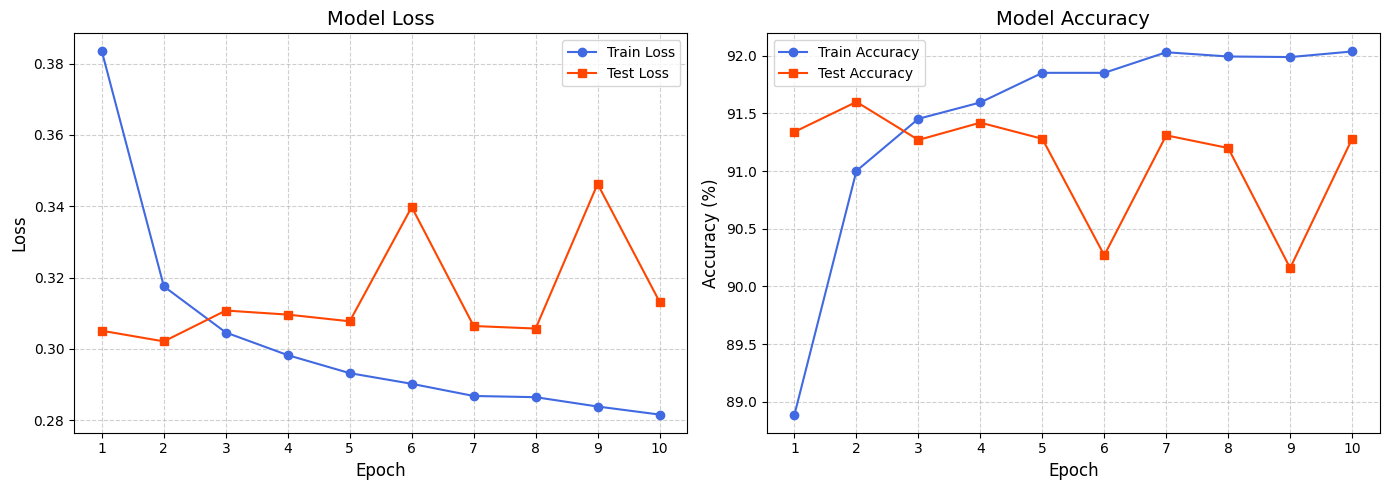

In [23]:
# =====================================================================
# 4. VẼ BIỂU ĐỒ TRỰC QUAN HÓA (MATPLOTLIB)
# =====================================================================
print("Biểu đồ trực quan...")
epochs_range = range(1, epochs + 1)

# Tạo khung hình gồm 1 dòng, 2 cột đồ thị
plt.figure(figsize=(14, 5))

# Đồ thị 1: Biểu diễn Loss qua từng epoch
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='royalblue', marker='o')
plt.plot(epochs_range, history['test_loss'], label='Test Loss', color='orangered', marker='s')
plt.title('Model Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(epochs_range)
plt.legend()

# Đồ thị 2: Biểu diễn Accuracy qua từng epoch
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='royalblue', marker='o')
plt.plot(epochs_range, history['test_acc'], label='Test Accuracy', color='orangered', marker='s')
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(epochs_range)
plt.legend()

# Tối ưu hóa khoảng cách giữa các đồ thị và hiển thị
plt.tight_layout()
plt.show()


In [4]:
#NLP

In [24]:
class MultilayerPerceptron:
    def __init__(self, input_dim=784, hidden_dim=128, num_classes=10, lr=0.1):
        self.lr = lr
        
        # --- Khởi tạo Trọng số tầng ẩn (Layer 1) sử dụng He (Kaiming) Initialization cho ReLU ---
        bound1 = math.sqrt(2.0 / input_dim)
        self.W1 = torch.randn(input_dim, hidden_dim) * bound1
        self.b1 = torch.zeros(1, hidden_dim)
        
        # --- Khởi tạo Trọng số tầng đầu ra (Layer 2) sử dụng Xavier cho Softmax ---
        bound2 = math.sqrt(6.0 / (hidden_dim + num_classes))
        self.W2 = (torch.rand(hidden_dim, num_classes) * 2 * bound2) - bound2
        self.b2 = torch.zeros(1, num_classes)
        
        # Bộ nhớ Cache lưu các giá trị trung gian cho quá trình Backward
        self.cache = {}
        
        # Khởi tạo các biến chứa Gradients toàn cục
        self.dW1, self.db1 = None, None
        self.dW2, self.db2 = None, None

    def forward(self, X):
        # Flatten ảnh về (Batch_size, 784)
        X = X.reshape(X.size(0), -1).float()
        
        # TẦNG ẨN (LAYER 1): Tuyến tính + Kích hoạt ReLU
        Z1 = torch.matmul(X, self.W1) + self.b1
        A1 = torch.clamp(Z1, min=0.0) # ReLU activation: max(0, Z1)
        
        # TẦNG ĐẦU RA (LAYER 2): Tuyến tính + Kích hoạt Softmax
        Z2 = torch.matmul(A1, self.W2) + self.b2
        
        # Ổn định số học cho Softmax
        max_z2 = torch.max(Z2, dim=1, keepdim=True)[0]
        exp_z2 = torch.exp(Z2 - max_z2)
        Y_hat = exp_z2 / torch.sum(exp_z2, dim=1, keepdim=True)
        
        # Lưu trữ tất cả các trạng thái kích hoạt vào cache
        self.cache = {'X': X, 'Z1': Z1, 'A1': A1, 'Y_hat': Y_hat}
        return Y_hat

    def backward(self, Y):
        # Lấy lại các giá trị từ cache
        X = self.cache['X']
        Z1 = self.cache['Z1']
        A1 = self.cache['A1']
        Y_hat = self.cache['Y_hat']
        
        m = Y.size(0)
        Y_one_hot = to_one_hot(Y, num_classes=Y_hat.size(1))
        
        # --- ĐẠO HÀM TẦNG 2 (Output Layer) ---
        dZ2 = (Y_hat - Y_one_hot) / m
        self.dW2 = torch.matmul(A1.t(), dZ2)
        self.db2 = torch.utils.data.dataloader.torch.sum(dZ2, dim=0, keepdim=True)
        
        # --- ĐẠO HÀM TẦNG 1 (Hidden Layer với ReLU) ---
        # Đạo hàm lan truyền ngược qua ma trận trọng số W2
        dA1 = torch.matmul(dZ2, self.W2.t())
        
        # Đạo hàm đi qua hàm kích hoạt ReLU: bằng dA1 nếu Z1 > 0, ngược lại bằng 0
        dZ1 = dA1.clone()
        dZ1[Z1 <= 0] = 0.0
        
        # Tính toán Gradients cho W1 và b1
        self.dW1 = torch.matmul(X.t(), dZ1)
        self.db1 = torch.sum(dZ1, dim=0, keepdim=True)

    def optimize_step(self):
        # Cập nhật đồng thời trọng số của cả 2 tầng (Gradient Descent)
        self.W1 -= self.lr * self.dW1
        self.b1 -= self.lr * self.db1
        self.W2 -= self.lr * self.dW2
        self.b2 -= self.lr * self.db2


In [25]:
# =====================================================================
# (TRAINING & TEST)
# =====================================================================
# Khởi tạo mạng MLP với 128 nút ẩn, học phí lr = 0.1
model = MultilayerPerceptron(input_dim=784, hidden_dim=128, num_classes=10, lr=0.1)
epochs = 10

history = {
    'train_loss': [], 'train_acc': [],
    'test_loss': [], 'test_acc': []
}

print("Quá trình huấn luyện mô hình MLP...")
print("-" * 60)

for epoch in range(epochs):
    # ----------------- TRAIN PHASE -----------------
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        Y_hat = model.forward(images)
        
        batch_size = labels.size(0)
        prob_correct_class = Y_hat[range(batch_size), labels]
        loss = -torch.sum(torch.log(prob_correct_class + 1e-9)) / batch_size
        running_loss += loss.item()
        
        _, predicted = torch.max(Y_hat, dim=1)
        total_train += batch_size
        correct_train += (predicted == labels).sum().item()
        
        model.backward(labels)
        model.optimize_step()
        
    epoch_train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    # ----------------- TEST PHASE -----------------
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for test_images, test_labels in test_loader:
            Y_hat_test = model.forward(test_images)

            t_batch_size = test_labels.size(0)
            prob_correct_class_test = Y_hat_test[range(t_batch_size), test_labels]
            test_loss = -torch.sum(torch.log(prob_correct_class_test + 1e-9)) / t_batch_size
            running_test_loss += test_loss.item()

            _, test_predicted = torch.max(Y_hat_test, dim=1)
            total_test += t_batch_size
            correct_test += (test_predicted == test_labels).sum().item()

    epoch_test_loss = running_test_loss / len(test_loader)
    test_accuracy = 100 * correct_test / total_test

    # Ghi lịch sử chỉ số
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(train_accuracy)
    history['test_loss'].append(epoch_test_loss)
    history['test_acc'].append(test_accuracy)

    print(f"Epoch [{epoch + 1}/{epochs}]")
    print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {train_accuracy:.2f}%")
    print(f"  [Test ] Loss: {epoch_test_loss:.4f} | Accuracy: {test_accuracy:.2f}%")
    print("-" * 60)

print("Mô hình MLP đã huấn luyện xong thành công!")

Quá trình huấn luyện mô hình MLP...
------------------------------------------------------------
Epoch [1/10]
  [Train] Loss: 0.2315 | Accuracy: 93.07%
  [Test ] Loss: 0.1310 | Accuracy: 96.06%
------------------------------------------------------------
Epoch [2/10]
  [Train] Loss: 0.1048 | Accuracy: 96.80%
  [Test ] Loss: 0.0962 | Accuracy: 96.93%
------------------------------------------------------------
Epoch [3/10]
  [Train] Loss: 0.0734 | Accuracy: 97.86%
  [Test ] Loss: 0.0834 | Accuracy: 97.37%
------------------------------------------------------------
Epoch [4/10]
  [Train] Loss: 0.0562 | Accuracy: 98.31%
  [Test ] Loss: 0.0811 | Accuracy: 97.48%
------------------------------------------------------------
Epoch [5/10]
  [Train] Loss: 0.0439 | Accuracy: 98.72%
  [Test ] Loss: 0.0705 | Accuracy: 97.81%
------------------------------------------------------------
Epoch [6/10]
  [Train] Loss: 0.0342 | Accuracy: 99.03%
  [Test ] Loss: 0.0765 | Accuracy: 97.73%
----------------

Biểu đồ trực quan MLP...


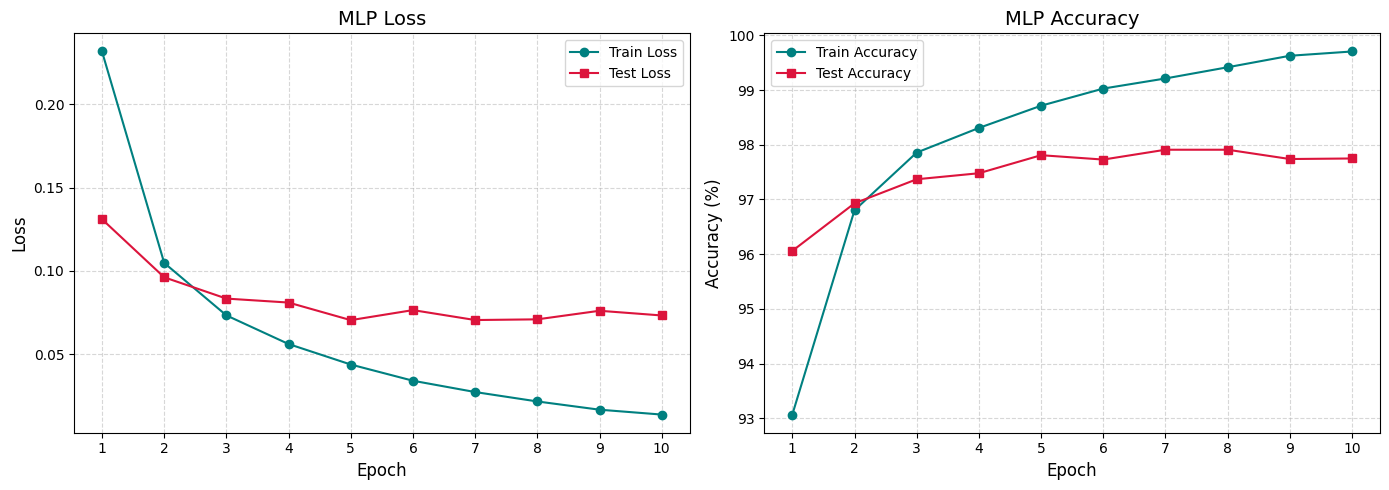

In [26]:
# =====================================================================
# 4. VẼ BIỂU ĐỒ SO SÁNH TRỰC QUAN HÓA
# =====================================================================
print("Biểu đồ trực quan MLP...")
epochs_range = range(1, epochs + 1)
plt.figure(figsize=(14, 5))

# Đồ thị Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='teal', marker='o')
plt.plot(epochs_range, history['test_loss'], label='Test Loss', color='crimson', marker='s')
plt.title('MLP Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(epochs_range)
plt.legend()

# Đồ thị Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='teal', marker='o')
plt.plot(epochs_range, history['test_acc'], label='Test Accuracy', color='crimson', marker='s')
plt.title('MLP Accuracy', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(epochs_range)
plt.legend()

plt.tight_layout()
plt.show()


In [27]:
# =====================================================================
# MÔ HÌNH CNN CHUẨN PYTORCH (NN.MODULE)
# =====================================================================
class PyTorchCNN(nn.Module):
    def __init__(self):
        super(PyTorchCNN, self).__init__()
        
        # Tầng tích chập 1: Nhận vào ảnh xám 1 kênh màu -> Trích xuất thành 16 kênh đặc trưng. Kernel kích thước 3x3.
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        
        # Tầng giảm mẫu (Max Pooling): Ô 2x2, bước trượt 2. Ảnh từ 28x28 giảm xuống còn 14x14.
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Tầng tích chập 2: Nhận vào 16 kênh đặc trưng -> Trích xuất thành 32 kênh đặc trưng sâu hơn.
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        
        # Tầng giảm mẫu tiếp theo: Ảnh từ 14x14 tiếp tục giảm xuống còn 7x7.
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # Tầng kết nối đầy đủ (Fully Connected): 32 kênh màu * kích thước phẳng 7x7 = 1568 biến đầu vào.
        self.fc = nn.Linear(32 * 7 * 7, 10)
        
    def forward(self, x):
        # Đi qua tầng tích chập và giảm mẫu số 1
        x = self.pool1(self.relu1(self.conv1(x)))
        
        # Đi qua tầng tích chập và giảm mẫu số 2
        x = self.pool2(self.relu2(self.conv2(x)))
        
        # Làm phẳng ma trận đặc trưng 2D thành vector 1D (Flatten)
        x = x.view(x.size(0), -1)
        
        # Đầu ra dự đoán tuyến tính logits (Hàm toán PyTorch CrossEntropyLoss sẽ tự tính Softmax bên trong)
        out = self.fc(x)
        return out

In [28]:
# Khởi tạo mô hình và chuyển sang thiết bị tương ứng (CPU/GPU)
model = PyTorchCNN().to(device)

# Hàm tính lỗi và Bộ tối ưu hóa Adam
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


# =====================================================================
# (TRAINING & TEST LOOP)
# =====================================================================
epochs = 10
history = {
    'train_loss': [], 'train_acc': [],
    'test_loss': [], 'test_acc': []
}

print("Quá trình huấn luyện mô hình PyTorch CNN...")
print("-" * 60)

for epoch in range(epochs):
    # ----------------- TRAIN PHASE -----------------
    model.train()  # Bật chế độ huấn luyện
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, labels in train_loader:
        # Chuyển dữ liệu sang GPU nếu có
        images = images.to(device)
        labels = labels.to(device)
        
        # Xóa các gradient cũ từ bước trước
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass và Cập nhật trọng số tự động
        loss.backward()
        optimizer.step()
        
        # Cộng dồn số liệu tính toán chỉ số trung bình
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct_train / total_train

    # ----------------- TEST PHASE -----------------
    model.eval()  # Chuyển sang chế độ đánh giá (tắt dropout/batchnorm nếu có)
    running_test_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():  # Không tính toán đồ thị gradient để tiết kiệm RAM/VRAM
        for test_images, test_labels in test_loader:
            test_images = test_images.to(device)
            test_labels = test_labels.to(device)
            
            test_outputs = model(test_images)
            t_loss = criterion(test_outputs, test_labels)
            
            running_test_loss += t_loss.item()
            _, test_predicted = torch.max(test_outputs.data, 1)
            total_test += test_labels.size(0)
            correct_test += (test_predicted == test_labels).sum().item()

    epoch_test_loss = running_test_loss / len(test_loader)
    test_accuracy = 100 * correct_test / total_test

    # Ghi lại lịch sử chỉ số vào dictionary
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(train_accuracy)
    history['test_loss'].append(epoch_test_loss)
    history['test_acc'].append(test_accuracy)

    print(f"Epoch [{epoch + 1}/{epochs}]")
    print(f"  [Train] Loss: {epoch_train_loss:.4f} | Accuracy: {train_accuracy:.2f}%")
    print(f"  [Test ] Loss: {epoch_test_loss:.4f} | Accuracy: {test_accuracy:.2f}%")
    print("-" * 60)

print("Mô hình PyTorch CNN đã hoàn tất huấn luyện!")

Quá trình huấn luyện mô hình PyTorch CNN...
------------------------------------------------------------
Epoch [1/10]
  [Train] Loss: 0.1672 | Accuracy: 95.08%
  [Test ] Loss: 0.0554 | Accuracy: 98.18%
------------------------------------------------------------
Epoch [2/10]
  [Train] Loss: 0.0582 | Accuracy: 98.24%
  [Test ] Loss: 0.0448 | Accuracy: 98.54%
------------------------------------------------------------
Epoch [3/10]
  [Train] Loss: 0.0422 | Accuracy: 98.73%
  [Test ] Loss: 0.0406 | Accuracy: 98.55%
------------------------------------------------------------
Epoch [4/10]
  [Train] Loss: 0.0343 | Accuracy: 98.92%
  [Test ] Loss: 0.0414 | Accuracy: 98.71%
------------------------------------------------------------
Epoch [5/10]
  [Train] Loss: 0.0281 | Accuracy: 99.14%
  [Test ] Loss: 0.0406 | Accuracy: 98.74%
------------------------------------------------------------
Epoch [6/10]
  [Train] Loss: 0.0240 | Accuracy: 99.21%
  [Test ] Loss: 0.0344 | Accuracy: 99.04%
--------

Biểu đồ CNN...


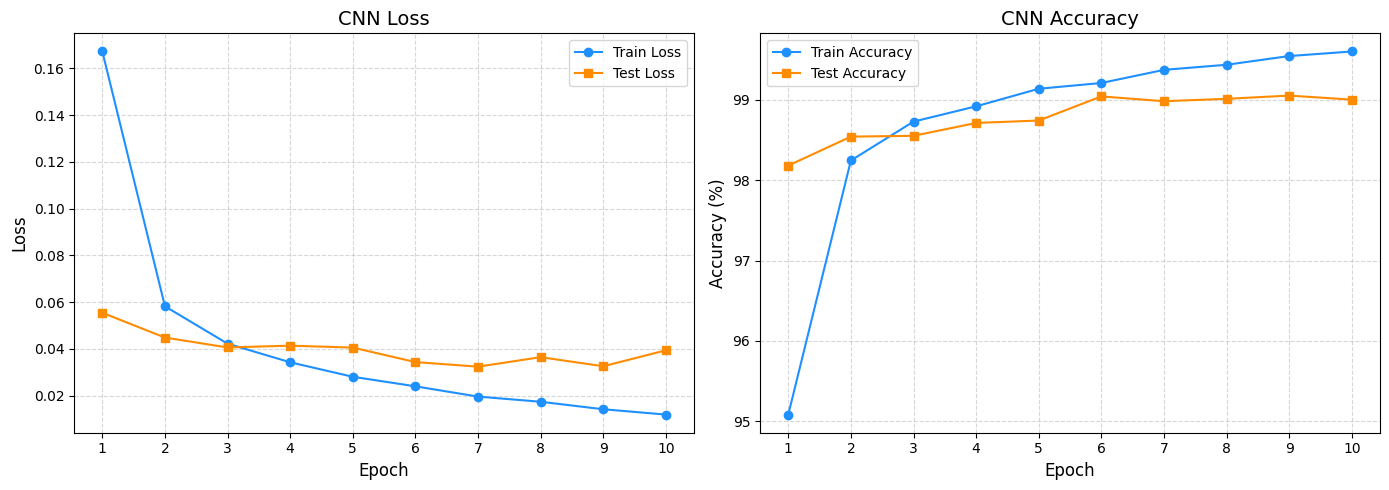

In [31]:
# =====================================================================
# 4. VẼ BIỂU ĐỒ THEO DÕI HIỆU NĂNG TỰ ĐỘNG
# =====================================================================
print("Biểu đồ CNN...")
epochs_range = range(1, epochs + 1)
plt.figure(figsize=(14, 5))

# Đồ thị Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='dodgerblue', marker='o')
plt.plot(epochs_range, history['test_loss'], label='Test Loss', color='darkorange', marker='s')
plt.title('CNN Loss', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(epochs_range)
plt.legend()

# Đồ thị Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='dodgerblue', marker='o')
plt.plot(epochs_range, history['test_acc'], label='Test Accuracy', color='darkorange', marker='s')
plt.title('CNN Accuracy', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(epochs_range)
plt.legend()

plt.tight_layout()
plt.show()


Quá trình thử nghiệm của 3 cách tiếp cận đã hoàn thành. Done Exercise 1.